In [2]:
!pip install seaborn scikit-learn pandas openpyxl


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


🏆 BOLETIM DE NOTAS FINAL - SPRINT 3
[1. Baseline Antigo (Regra Ingênua/Lag 1)]
MAE: 6.46 | RMSE: 8.90 | MAPE: 26.82%

[2. Modelo ML Inicial (Configuração de Fábrica)]
MAE: 7.33 | RMSE: 9.07 | MAPE: 31.74%

[3. Modelo ML Tunado (Random Search Otimizado)]
MAE: 7.00 | RMSE: 8.25 | MAPE: 31.36%



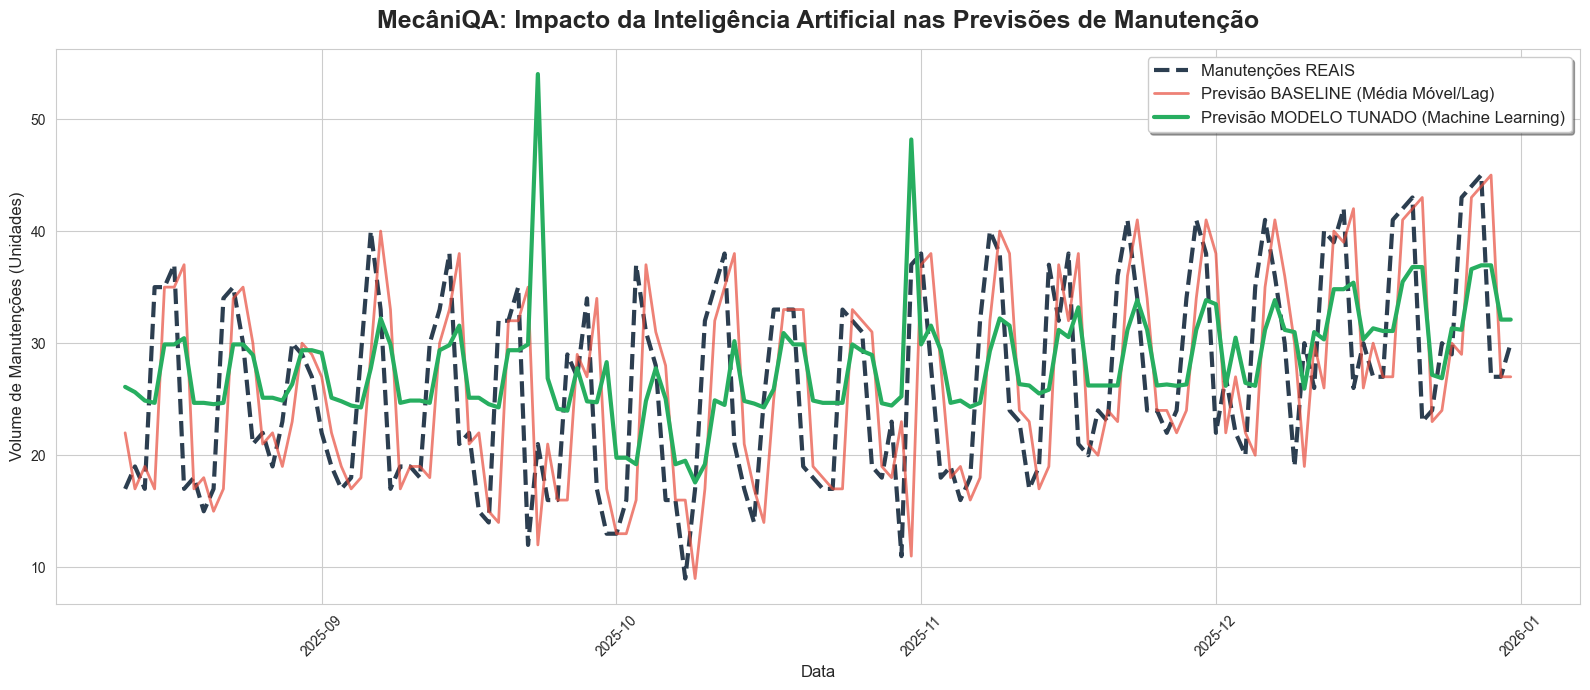

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# 1. PREPARANDO OS DADOS
try:
    df = pd.read_excel('datasets/mecaniqa_dataset.xlsx')
    df['Data'] = pd.to_datetime(df['Data'])
    df = df.sort_values('Data').set_index('Data')
except:
    print("Aviso: Excel não encontrado. Usando dados simulados.")
    datas = pd.date_range(start='2026-01-01', periods=200, freq='D')
    df = pd.DataFrame({'manutencoes': np.random.poisson(20, 200)}, index=datas)

alvo = df.columns[0]
df['lag_1'] = df[alvo].shift(1)
df['media_movel_7d'] = df[alvo].shift(1).rolling(window=7).mean()
df = df.dropna()

X = df[['lag_1', 'media_movel_7d']]
y = df[alvo]

tamanho_treino = int(len(df) * 0.8)
X_train, X_test = X.iloc[:tamanho_treino], X.iloc[tamanho_treino:]
y_train, y_test = y.iloc[:tamanho_treino], y.iloc[tamanho_treino:]

# 2. TREINANDO OS MODELOS RAPIDAMENTE
rf_inicial = RandomForestRegressor(random_state=42)
rf_inicial.fit(X_train, y_train)
rf_pred = rf_inicial.predict(X_test)

param_dist = {'n_estimators': [50, 100, 200], 'max_depth': [3, 5, 10]}
tscv = TimeSeriesSplit(n_splits=3)
rs = RandomizedSearchCV(RandomForestRegressor(random_state=42), param_distributions=param_dist, n_iter=5, cv=tscv, random_state=42, n_jobs=-1)
rs.fit(X_train, y_train)
pred_tunada_rs = rs.predict(X_test)

baseline_pred = X_test['lag_1']

# 3. BOLETIM DE NOTAS E PLOTAGEM DEFINITIVA
def calcular_e_imprimir_metricas(y_real, y_previsto, nome_cenario):
    mae = mean_absolute_error(y_real, y_previsto)
    rmse = np.sqrt(mean_squared_error(y_real, y_previsto))
    mape = mean_absolute_percentage_error(y_real, y_previsto) * 100
    print(f"[{nome_cenario}]")
    print(f"MAE: {mae:.2f} | RMSE: {rmse:.2f} | MAPE: {mape:.2f}%\n")

print("🏆 BOLETIM DE NOTAS FINAL - SPRINT 3\n" + "="*50)
calcular_e_imprimir_metricas(y_test, baseline_pred, "1. Baseline Antigo (Regra Ingênua/Lag 1)")
calcular_e_imprimir_metricas(y_test, rf_pred, "2. Modelo ML Inicial (Configuração de Fábrica)")
calcular_e_imprimir_metricas(y_test, pred_tunada_rs, "3. Modelo ML Tunado (Random Search Otimizado)")
print("="*50)

plt.figure(figsize=(16, 7))
sns.set_style("whitegrid")

plt.plot(y_test.index, y_test.values, label='Manutenções REAIS', color='#2c3e50', linewidth=3, linestyle='dashed')
plt.plot(y_test.index, baseline_pred.values, label='Previsão BASELINE (Média Móvel/Lag)', color='#e74c3c', linewidth=2, alpha=0.7)
plt.plot(y_test.index, pred_tunada_rs, label='Previsão MODELO TUNADO (Machine Learning)', color='#27ae60', linewidth=3)

plt.title('MecâniQA: Impacto da Inteligência Artificial nas Previsões de Manutenção', fontsize=18, fontweight='bold', pad=15)
plt.xlabel('Data', fontsize=12)
plt.ylabel('Volume de Manutenções (Unidades)', fontsize=12)
plt.legend(loc='best', fontsize=12, frameon=True, shadow=True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()